# First buckling of blade-stiffened CFRP curved panels

Abramovich et al. [1] tested in axial compression nine curved panels of
graphite-epoxy (Hexcel IM7/8552), PSC1 to PSC9, stiffened by co-cured blade
stringers, measured the load of the first local buckle of the skin between
the stringers and the collapse load, and compared them with a linear
buckling analysis of MSC/NASTRAN. Abramovich and Weller [2] tabulated these
results again with those of other panels of the same series, the material
constants and the dimensions of the stringer. The panels belong to three
configurations:

| configuration | panels | blades | blade height $h_s$ |
|---|---|---|---|
| A | PSC1, PSC2, PSC4 | 5 | 20 mm |
| B | PSC3, PSC5, PSC6 | 5 | 15 mm |
| C | PSC7, PSC8, PSC9 | 6 | 20 mm |

Here the first buckling load of each configuration is computed with a
linear buckling analysis of a model of discrete stringers:

- the skin with the BFSC cylinder element of Sanders-type kinematics,
  `BFSCCylinderSanders`;
- the T-shaped stringer assembled from plates: the stepped foot, a plate
  bonded on the inner surface of the skin, and the blade, a plate of BFSC
  plate elements `BFSCPlate2D` of
  [bfscplate2d](https://github.com/saullocastro/bfscplate2d) standing on
  the middle of the foot, in the plane $(x, r)$, connected to the skin and
  foot along their common line.

The model is given by the module `composite_stiffened_shell.py`, next to
this notebook, which is also used in [Buckling of a CFRP stringer-stiffened
cylinder under axial compression and
torsion](lanzi2003_stiffened_cylinder.ipynb). Besides `bfsccylinder`, it
needs `bfscplate2d`, `composites`, `structsolve` and Matplotlib.

## Data of the panels

All values in N and mm. Each value is given with the place where it was
read:

| quantity | value | source |
|---|---|---|
| material | Hexcel IM7 (12K)/8552 | [1] p. 2, [2] Section 2 |
| $E_{11}$, $E_{22}$, $G_{12}$ | 147300, 11800, 6000 N/mm$^2$ | [2] Table 1 |
| $\nu_{12}$ | 0.3 | [2] Table 1 |
| ply thickness | 0.125 mm | [1] p. 2, [2] Table 1 |
| radius $R$ | 938 mm | [1] p. 2 and Fig. 1c, [2] Section 2 |
| length | 720 mm, of which two end pieces of 30 mm | [1] p. 2 and Fig. 1c |
| free length $L$ | 660 mm | [1] Fig. 1c (30.0, 660.0, 30.0) |
| arc length | 680 mm | [1] Fig. 1c, [2] Section 2 |
| skin lay-up | $(0, \pm 45, 90)_S$ | [1] p. 2, [2] Section 2 |
| stringer lay-up | $(\pm 45, 0_2)_{3S}$ | [1] p. 2 |
| stringers, A and B | 5, spacing 544.0/4 = 136 mm, 68.0 mm from the edges | [1] Fig. 1c, section A-A of assemblies 501, 502 |
| stringers, C | 6, spacing 566.7/5 = 113.34 mm, 56.7 mm from the edges | [1] Fig. 1c, section A-A of assembly 503 |
| blade height $h_s$ | 20 mm (A, C), 15 mm (B) | [1] Table 1, [2] Table 3 |
| blade | 3 mm thick; tip 21 mm from the outer surface of the 1 mm skin | [2] Fig. 1, top |
| foot | 60 mm wide, stepped: skin plus foot 2.50 mm thick over the middle 20 mm, 2 mm over 40 mm, 1.50 mm over 60 mm; fillets of radius 2 mm | [2] Fig. 1, top |

The 24 plies of 0.125 mm of $(\pm 45, 0_2)_{3S}$ give the 3 mm of the blade
of [2] Fig. 1, and the 8 plies of the skin its 1 mm. The tip of the blade
at 21 mm from the outer surface of the skin, [2] Fig. 1, is 20 mm from its
inner surface, the height $h_s$ of [2] Table 3; the same reference is
assumed for $h_s$ = 15 mm. The material constants of [2] Table 1 are given
for the panels AXIAL1 to AXIAL4, of the same material as the PSC panels
([2] Section 2); the transverse shear moduli, not given, are not used by
the elements, whose kinematics neglect transverse shear. The pattern of
6 stringers, $2 \times 56.7 + 566.7$ = 680.1 mm, is centred on the arc
length of 680 mm.

Section D-D of [1] Fig. 1c shows the panel embedded in the end pieces of
30 mm; in the model the skin and the blades are loaded together by the
end pieces. Fig. 4 of [1] shows the panel in the testing machine
with longitudinal fixture plates along the unloaded edges; the restraint
that they give is not described.

In [1]:
%matplotlib inline
import time

import numpy as np
import matplotlib.pyplot as plt
from composites import laminated_plate

from composite_stiffened_shell import (StiffenedShell, node_coordinates,
                                       plot_skin_w)

# [2] Table 1, N/mm^2; transverse shear moduli not used (Kirchhoff elements)
E11, E22, G12, nu12 = 147300., 11800., 6000., 0.3
laminaprop = (E11, E22, nu12, G12, G12, G12)
tp = 0.125  # ply thickness, [1] p. 2
R = 938.  # [1] p. 2
L = 660.  # free length, [1] Fig. 1c
arc = 680.  # [1] Fig. 1c

skin_stack = [0, 45, -45, 90, 90, -45, 45, 0]  # (0, +-45, 90)_S
half = [45, -45, 0, 0]*3  # (+-45, 0_2)_3
blade_stack = half + half[::-1]  # (+-45, 0_2)_3S
h_skin = len(skin_stack)*tp
t_blade = len(blade_stack)*tp
print('skin %.3f mm, blade %.3f mm thick' % (h_skin, t_blade))

configurations = {
    'A': dict(panels='PSC1, PSC2, PSC4', nblades=5, hs=20.,
              spacing=544.0/4),
    'B': dict(panels='PSC3, PSC5, PSC6', nblades=5, hs=15.,
              spacing=544.0/4),
    'C': dict(panels='PSC7, PSC8, PSC9', nblades=6, hs=20.,
              spacing=566.7/5),
}
for k, c in configurations.items():
    c['edge'] = (arc - (c['nblades'] - 1)*c['spacing'])/2
    print('%s: %d blades, h_s = %.0f mm, spacing %.2f mm, '
          'first blade %.2f mm from the edge'
          % (k, c['nblades'], c['hs'], c['spacing'], c['edge']))

skin 1.000 mm, blade 3.000 mm thick
A: 5 blades, h_s = 20 mm, spacing 136.00 mm, first blade 68.00 mm from the edge
B: 5 blades, h_s = 15 mm, spacing 136.00 mm, first blade 68.00 mm from the edge
C: 6 blades, h_s = 20 mm, spacing 113.34 mm, first blade 56.65 mm from the edge


## The stringer: blade and stepped foot

The blade stringer of [2] Fig. 1 is a T: the two halves of the blade
laminate, 12 plies each, turn at the root into the two flanges of the
foot, which end in two steps of 4 plies: the foot is 12 plies (1.5 mm)
thick over the middle 20 mm, 8 plies (1.0 mm) from 10 to 20 mm on each side
of the blade and 4 plies (0.5 mm) from 20 to 30 mm, which gives the total
thicknesses of skin and foot of 2.50, 2 and 1.50 mm of the figure.

The model has the plates:

- the **skin**, BFSC cylinder elements on the mid-surface of radius $R$;
- the **foot**, six strips of 10 mm bonded on the inner surface of the
  skin, each a laminate of BFSC cylinder elements on the nodes of the skin
  whose stiffness matrices $\boldsymbol{A}$, $\boldsymbol{B}$,
  $\boldsymbol{D}$ are referred to the mid-surface of the skin through the
  offset of its plies, $-(h_{skin} + t_{foot})/2$: a perfect bond, skin and
  foot sharing the normal of the Kirchhoff hypothesis, the stiffnesses of
  the two plates adding up;
- the **blade**, a plate of BFSC plate elements in the plane $(x, r)$, on
  the line of the middle of the foot, from the mid-surface of the skin to
  the tip, of height $h_s + h_{skin}/2$, with the translations and the
  rotation about $x$ of its root equal to those of the skin
  (see the docstring of the module).

Within the foot, the plies of a flange are those of a half of the blade,
in the order they have at the root: the plies of the middle of the blade,
$0_2$, on the skin, the $45$ of the faces of the blade on the free surface
of the foot, and the two flanges mirror images of each other ($+45$ of
one flange is $-45$ of the other). The plies that end at the two steps are
not given in [1, 2]. The model drops whole repeats $[0_2/-45/45]$ (listed
from the skin), one at each step: the three repeats of a flange are equal,
so that the laminate of a step is the same whichever repeat ends there,
the one farthest from the skin, the one next to it or the middle one.
Two other schemes, which drop first the plies of one orientation, are
computed in the section "Sensitivity to the ply drops" below. The fillets of radius
2 mm and the filler at the root are not modelled. The blade plate overlaps
the skin and the 1.5 mm of the foot over its first 2 mm, which adds
$3 \times 2$ = 6 mm$^2$ to the 61.5 mm$^2$ of a blade of $h_s$ = 20 mm.

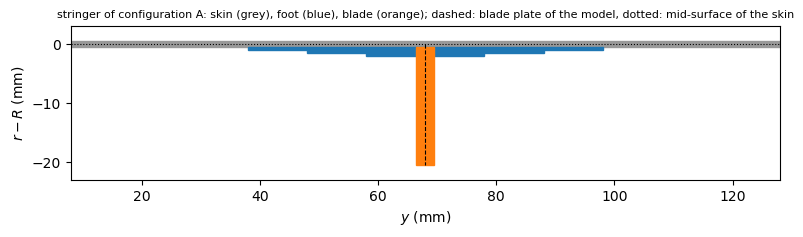

In [2]:
# flange plies listed from the skin side, flange at y > y_s
from_skin = [0, 0, -45, 45]*3
# plies (indices of from_skin) kept in the steps of 8 and 4 plies; the plies
# that end at a step are those farthest from the skin among those dropped
drop_schemes = {
    'whole repeats': ([0, 1, 2, 3, 4, 5, 6, 7], [0, 1, 2, 3]),
    '0 plies first': ([0, 1, 2, 3, 6, 7, 10, 11], [2, 3, 6, 7]),
    '+-45 plies first': ([0, 1, 2, 3, 4, 5, 8, 9], [0, 1, 4, 5]),
}


def foot_laminates(scheme='whole repeats'):
    keep = {12: list(range(12)), 8: drop_schemes[scheme][0],
            4: drop_schemes[scheme][1]}
    feet = {}
    for n in (12, 8, 4):
        right = [from_skin[i] for i in keep[n]]
        left = [-a for a in right]
        offset = -(h_skin/2 + n*tp/2)
        # composites lists the plies from the bottom (inner) to the top
        feet[('right', n)] = laminated_plate(right[::-1], plyt=tp,
                                             laminaprop=laminaprop,
                                             offset=offset)
        feet[('left', n)] = laminated_plate(left[::-1], plyt=tp,
                                            laminaprop=laminaprop,
                                            offset=offset)
    return feet


skin = laminated_plate(skin_stack, plyt=tp, laminaprop=laminaprop)
blade = laminated_plate(blade_stack, plyt=tp, laminaprop=laminaprop)
feet = foot_laminates()


def build(config, n_edge, n_foot, n_bay, nx, nh, clamped_sides=False,
          feet=feet):
    c = configurations[config]
    nb, sp, edge = c['nblades'], c['spacing'], c['edge']
    segments = [(edge - 30., n_edge)]
    for k in range(nb):
        segments += [(10., n_foot)]*6
        if k < nb - 1:
            segments += [(sp - 60., n_bay)]
    segments += [(edge - 30., n_edge)]
    y = node_coordinates(segments)
    model = StiffenedShell(R, L, y, False, nx, skin)
    for k in range(nb):
        ys = edge + k*sp
        for n, d1, d2 in [(12, 0., 10.), (8, 10., 20.), (4, 20., 30.)]:
            model.add_plate(feet[('right', n)], ys + d1, ys + d2)
            model.add_plate(feet[('left', n)], ys - d2, ys - d1)
        model.add_blade(ys, c['hs'] + h_skin/2, blade, nh, 'internal')
    model.build()
    # loaded edges: clamped in the end pieces, x = L moved by the platen
    model.clamp_end(0)
    mu, mv = model.rigid_end(-1)
    model.fixed.add(mv)
    # unloaded edges in the fixture plates
    model.support_side(0, clamped_sides)
    model.support_side(-1, clamped_sides)
    model.finalize()
    return model, mu


fig, ax = plt.subplots(figsize=(8, 2.2))
c = configurations['A']
ys = c['edge']
ax.add_patch(plt.Rectangle((ys - 60, -h_skin/2), 120, h_skin, color='0.6'))
for n, d1, d2 in [(12, 0., 10.), (8, 10., 20.), (4, 20., 30.)]:
    for s in (1, -1):
        y1, y2 = sorted((ys + s*d1, ys + s*d2))
        ax.add_patch(plt.Rectangle((y1, -h_skin/2 - n*tp), y2 - y1, n*tp,
                                   color='tab:blue'))
ax.add_patch(plt.Rectangle((ys - t_blade/2, -h_skin/2 - c['hs']), t_blade,
                           c['hs'], color='tab:orange'))
ax.plot([ys, ys], [0, -h_skin/2 - c['hs']], 'k--', lw=0.8)
ax.plot([ys - 60, ys + 60], [0, 0], 'k:', lw=0.8)
ax.set_xlim(ys - 60, ys + 60)
ax.set_ylim(-23, 3)
ax.set_aspect('equal')
ax.set_xlabel('$y$ (mm)')
ax.set_ylabel('$r - R$ (mm)')
ax.set_title('stringer of configuration A: skin (grey), foot (blue), blade '
             '(orange); dashed: blade plate of the model, dotted: '
             'mid-surface of the skin', fontsize=8)
plt.tight_layout()
plt.show()

## Boundary conditions, load and analysis

The loaded edges are held in the end pieces of 30 mm and loaded by the
platens of the testing machine [1]: the edge $x = 0$ is clamped, $u = v = w
= w_{,x} = 0$ for the skin and $U = V = W = W_{,X} = 0$ for the blades, and
the edge $x = L$ is clamped to a rigid platen that moves along $x$ only: a
uniform $u = U$, with $v = w = w_{,x} = 0$ and $V = W = W_{,X} = 0$. The
axial force $P$ is applied to the platen, a single degree of freedom of
the model (see `StiffenedShell.rigid_end`), and the axial stiffness of the
panel is $P/\delta$, with $\delta$ the shortening of the static solution.

The unloaded edges $y = 0$ and $y = 680$ mm are supported by the fixture
plates, with $w = 0$ and $u$, $v$ free; two cases bound the unknown
rotational restraint: simply supported, $w_{,y}$ free, and clamped,
$w_{,y} = 0$.

As in all the models of `bfsccylinder`, the derivatives along an edge of
the displacements prescribed on it are prescribed as well: at a clamped
end $u_{,y} = v_{,y} = w_{,y} = w_{,xy} = 0$ for the skin and $U_{,Y} =
V_{,Y} = W_{,Y} = W_{,XY} = 0$ for the blades (at the rigid platen $u$
uniform, so that $u_{,y} = 0$ too), and along a simply supported unloaded
edge, $w = 0$, also $w_{,x} = 0$, with $w_{,y} = w_{,xy} = 0$ when it is
clamped.

The pre-buckling state is the linear static solution $\boldsymbol{u}_0$ of
$\boldsymbol{K}_{C0} \boldsymbol{u}_0 = \boldsymbol{F}$ for a unit force on
the platen, and the geometric stiffness matrix $\boldsymbol{K}_G$ of the
membrane forces of $\boldsymbol{u}_0$, with the in-plane terms of the
blades, gives the linear buckling problem

$$(\boldsymbol{K}_{C0} + \lambda \boldsymbol{K}_G)\boldsymbol{\phi} =
\boldsymbol{0}$$

solved with `structsolve.lb`; the first buckling load is $\lambda_1 P$. See
[Analyses](../analyses.rst) for the matrices of the BFSC cylinder element.
The local modes of the skin between the stringers have close eigenvalues,
one for each bay and combination of bays, so that more eigenvalues than
the lowest one are requested, which also speeds up the convergence of the
eigensolver.

In [3]:
def analyse(config, mesh, clamped_sides=False, num_eigvalues=10,
            feet=feet):
    t0 = time.time()
    model, mu = build(config, *mesh, clamped_sides=clamped_sides,
                      feet=feet)
    P = 1.  # N
    lam, modes, u0 = model.buckling({mu: -P}, num_eigvalues=num_eigvalues)
    out = dict(model=model, Pcr=lam*P, modes=modes, k=P/(-u0[mu]),
               dofs=model.Nr, time=time.time() - t0)
    return out

## Mesh convergence

Configuration A with simply supported unloaded edges, meshes of `n_edge`
elements between the edge of the panel and the first foot, `n_foot`
elements across each 10 mm strip of the foot, `n_bay` elements between two
feet, `nx` nodes along $x$ and `nh` elements along the height of a blade:

In [4]:
meshes = [(2, 1, 4, 23, 2), (3, 1, 6, 34, 3), (4, 1, 8, 45, 3),
          (6, 2, 12, 67, 4)]
conv = []
for mesh in meshes:
    r = analyse('A', mesh)
    conv.append(r)
    print('mesh %-18s %6d dofs: P_cr = %s kN, P/delta = %.1f kN/mm, %.0f s'
          % (mesh, r['dofs'], np.array2string(r['Pcr'][:3]/1e3, precision=2),
             r['k']/1e3, r['time']))
for r0, r1 in zip(conv[:-1], conv[1:]):
    print('change of P_cr from %s to %s: %.2f %%'
          % (r0['dofs'], r1['dofs'],
             100*(r1['Pcr'][0] - r0['Pcr'][0])/r1['Pcr'][0]))

mesh (2, 1, 4, 23, 2)    13201 dofs: P_cr = [99.39 99.58 99.96] kN, P/delta = 139.2 kN/mm, 13 s


mesh (3, 1, 6, 34, 3)    24837 dofs: P_cr = [99.01 99.18 99.57] kN, P/delta = 139.2 kN/mm, 32 s


mesh (4, 1, 8, 45, 3)    37603 dofs: P_cr = [98.91 99.08 99.47] kN, P/delta = 139.2 kN/mm, 70 s


mesh (6, 2, 12, 67, 4)   92625 dofs: P_cr = [98.78 98.94 99.34] kN, P/delta = 139.2 kN/mm, 290 s
change of P_cr from 13201 to 24837: -0.39 %
change of P_cr from 24837 to 37603: -0.10 %
change of P_cr from 37603 to 92625: -0.14 %


The first buckling load changes by less than 0.2 % from the third mesh to
the finest one, and by less than 1 % from the coarsest; the third mesh,
`(4, 1, 8, 45, 3)`, is used below for the three configurations.

In [5]:
mesh = (4, 1, 8, 45, 3)
results = {}
for config in configurations:
    for clamped in (False, True):
        r = analyse(config, mesh, clamped_sides=clamped)
        results[(config, clamped)] = r
        print('%s, unloaded edges %-16s: P_cr = %6.1f kN, '
              'P/delta = %.1f kN/mm, %.0f s'
              % (config, 'clamped' if clamped else 'simply supported',
                 r['Pcr'][0]/1e3, r['k']/1e3, r['time']))

A, unloaded edges simply supported: P_cr =   98.9 kN, P/delta = 139.2 kN/mm, 73 s


A, unloaded edges clamped         : P_cr =   98.9 kN, P/delta = 139.2 kN/mm, 72 s


B, unloaded edges simply supported: P_cr =   92.4 kN, P/delta = 129.5 kN/mm, 67 s


B, unloaded edges clamped         : P_cr =   92.4 kN, P/delta = 129.5 kN/mm, 70 s


C, unloaded edges simply supported: P_cr =  150.0 kN, P/delta = 155.1 kN/mm, 95 s


C, unloaded edges clamped         : P_cr =  150.0 kN, P/delta = 155.1 kN/mm, 97 s


## Comparison with the tests and with MSC/NASTRAN

The first buckling loads of the tests are those of [1] Table 1 and [2]
Table 3 (the same values), the loads at which the first local buckle was
seen (Moiré fringes, strain gages); the theoretical values are the linear
buckling loads of MSC/NASTRAN of [1] Table 1. The collapse loads of PSC7 to
PSC9 differ between [1] Table 1 (280.0, 270.0, 280.0 kN) and [2] Table 3
(228.5, 240.0, 244.0 kN, equal to the first buckling loads); they are not
compared here. The relative differences are those of the present model,
with simply supported (SS) and clamped (CC) unloaded edges:

In [6]:
# [1] Table 1 and [2] Table 3, kN
tests = {'A': {'PSC1': 131.0, 'PSC2': 150.0, 'PSC4': 158.5},
         'B': {'PSC3': 136.0, 'PSC5': 113.0, 'PSC6': 126.0},
         'C': {'PSC7': 228.5, 'PSC8': 240.0, 'PSC9': 244.0}}
nastran = {'A': 92., 'B': 89., 'C': 139.}  # [1] Table 1, kN

print('conf.  present SS  present CC | reference                 value  '
      '(SS - ref)/ref')
for config in configurations:
    Pss = results[(config, False)]['Pcr'][0]/1e3
    Pcc = results[(config, True)]['Pcr'][0]/1e3
    refs = [('MSC/NASTRAN [1]', nastran[config])]
    refs += [('test ' + k, v) for k, v in tests[config].items()]
    mean = np.mean(list(tests[config].values()))
    refs += [('mean of the tests', mean)]
    for i, (name, val) in enumerate(refs):
        head = ('%-6s %8.1f %11.1f' % (config, Pss, Pcc) if i == 0
                else ' '*26)
        print('%s | %-22s %8.1f  %+7.1f %%'
              % (head, name, val, 100*(Pss - val)/val))

conf.  present SS  present CC | reference                 value  (SS - ref)/ref
A          98.9        98.9 | MSC/NASTRAN [1]            92.0     +7.5 %
                           | test PSC1                 131.0    -24.5 %
                           | test PSC2                 150.0    -34.1 %
                           | test PSC4                 158.5    -37.6 %
                           | mean of the tests         146.5    -32.5 %
B          92.4        92.4 | MSC/NASTRAN [1]            89.0     +3.8 %
                           | test PSC3                 136.0    -32.1 %
                           | test PSC5                 113.0    -18.3 %
                           | test PSC6                 126.0    -26.7 %
                           | mean of the tests         125.0    -26.1 %
C         150.0       150.0 | MSC/NASTRAN [1]           139.0     +7.9 %
                           | test PSC7                 228.5    -34.4 %
                           | test PSC8               

## Buckling modes

The normal displacement $w$ of the skin of the first mode of each
configuration, simply supported unloaded edges, over the developed panel
seen from the outside, with the blades as lines:

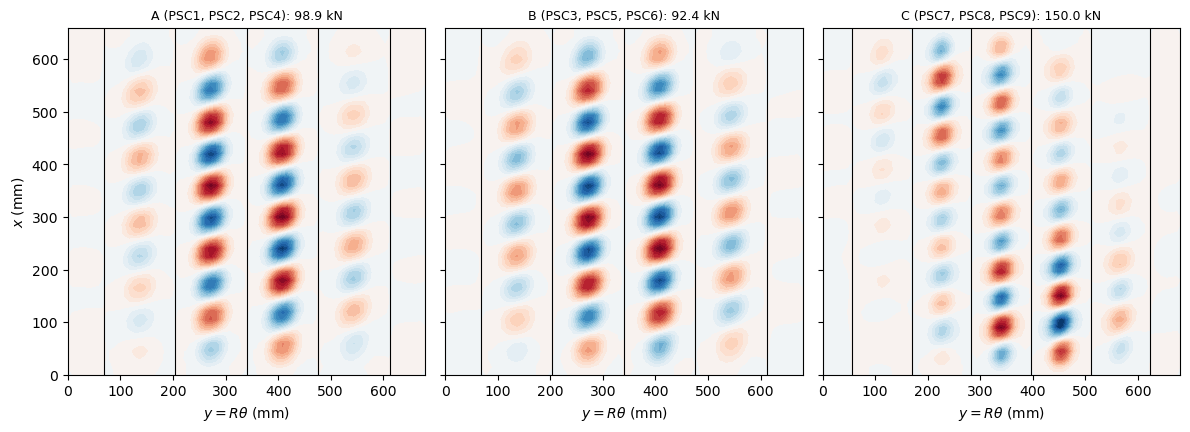

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.5), sharey=True)
for ax, config in zip(axes, configurations):
    r = results[(config, False)]
    plot_skin_w(ax, r['model'], r['modes'][:, 0],
                '%s (%s): %.1f kN' % (config, configurations[config]['panels'],
                                      r['Pcr'][0]/1e3))
axes[0].set_ylabel('$x$ (mm)')
plt.tight_layout()
plt.show()

The ten lowest buckling loads of each configuration, which are modes of
the skin between the stringers in different bays and combinations of bays:

In [8]:
for config in configurations:
    r = results[(config, False)]
    print(config, np.array2string(r['Pcr']/1e3, precision=1))

A [ 98.9  99.1  99.5  99.5  99.9 100.  100.1 100.2 101.1 101.7]
B [92.4 92.5 92.8 92.8 93.2 93.3 93.4 93.5 94.4 94.8]
C [150.  150.2 150.5 151.1 151.5 151.9 152.  152.1 152.3 152.7]


## Sensitivity to the ply drops

Neither [1] nor [2] gives the plies that end at the two steps of the foot.
Besides the whole repeats of the model, two schemes bound the plausible
ones: the $0$ plies end first (the step of 8 plies keeps the two $0$
plies next to the skin and the six $\pm 45$ plies, the step of 4 plies
two pairs $-45/45$), or the $\pm 45$ plies end first (the step of 8 plies
keeps the six $0$ plies and the pair $-45/45$ next to the skin, the step
of 4 plies four $0$ plies). In each scheme, among the plies of an
orientation, those farthest from the skin end first. The laminates of the
steps, listed from the skin:

In [9]:
for scheme, (k8, k4) in drop_schemes.items():
    print('%-17s 8 plies %s, 4 plies %s'
          % (scheme, [from_skin[i] for i in k8], [from_skin[i] for i in k4]))

whole repeats     8 plies [0, 0, -45, 45, 0, 0, -45, 45], 4 plies [0, 0, -45, 45]
0 plies first     8 plies [0, 0, -45, 45, -45, 45, -45, 45], 4 plies [-45, 45, -45, 45]
+-45 plies first  8 plies [0, 0, -45, 45, 0, 0, 0, 0], 4 plies [0, 0, 0, 0]


In [10]:
sens = {}
for scheme in drop_schemes:
    for config in configurations:
        if scheme == 'whole repeats':
            r = results[(config, False)]
        else:
            r = analyse(config, mesh, feet=foot_laminates(scheme))
        sens[(scheme, config)] = r['Pcr'][0]/1e3
print('%-17s' % 'scheme' + ''.join('%14s' % ('%s (kN)' % c)
                                  for c in configurations)
      + '   diff. from MSC/NASTRAN [1]')
for scheme in drop_schemes:
    print('%-17s' % scheme
          + ''.join('%14.1f' % sens[(scheme, c)] for c in configurations)
          + '   ' + ', '.join('%+.1f %%' % (100*(sens[(scheme, c)]/nastran[c]
                                                 - 1))
                              for c in configurations))
print('%-17s' % 'MSC/NASTRAN [1]'
      + ''.join('%14.1f' % nastran[c] for c in configurations))

scheme                   A (kN)        B (kN)        C (kN)   diff. from MSC/NASTRAN [1]
whole repeats              98.9          92.4         150.0   +7.5 %, +3.8 %, +7.9 %
0 plies first              94.2          87.5         144.7   +2.4 %, -1.7 %, +4.1 %
+-45 plies first           97.9          91.9         139.5   +6.4 %, +3.3 %, +0.4 %
MSC/NASTRAN [1]            92.0          89.0         139.0


## Discussion

**Modes.** The lowest modes are local modes of the skin between the feet
of the stringers, with about ten axial half-waves in each bay, largest in
the middle bays and of opposite sign in neighbouring bays, the lines of
the blades remaining nearly straight. The ten lowest loads of each
configuration are within 3 % of each other: they are combinations of the
modes of the four (five) inner bays, which are almost uncoupled. The
unloaded edges, simply supported or clamped, change the first buckling
load by less than 0.1 kN: the edge bays, 38 mm (A, B) and 26.7 mm (C)
wide between the edge and the foot, are much stiffer than the inner bays,
76 mm (A, B) and 53.3 mm (C) wide between two feet.

**MSC/NASTRAN.** The present first buckling loads are 7.5 %, 3.8 % and
7.9 % above those of MSC/NASTRAN of [1] for A, B and C. Both are linear
buckling analyses of the perfect panel, and the ratio of configurations C
and A is almost the same, 1.52 here and 1.51 for MSC/NASTRAN; [1] does not
describe its model, so that the differences cannot be traced. Here they
depend on the modelling of the stepped foot, bonded on the skin with its
full stiffness, on the overlap of the blade with the skin and the foot,
and on the plies that end at the steps of the foot.

**Ply drops.** The plies that end at the steps of the foot, not given in
[1, 2], change the first buckling load by up to 7 %: whole repeats give the
highest loads, 98.9, 92.4 and 150.0 kN for A, B and C; the $0$ plies ending
first give 94.2, 87.5 and 144.7 kN ($-4.8$, $-5.3$ and $-3.5$ %), +2.4,
$-1.7$ and +4.1 % from MSC/NASTRAN; the $\pm 45$ plies ending first give
97.9, 91.9 and 139.5 kN ($-1.0$, $-0.5$ and $-7.0$ %), +6.4, +3.3 and
+0.4 % from MSC/NASTRAN. All three schemes are within $-1.7$ to +7.9 %
of MSC/NASTRAN; the model above uses whole repeats.

**The panels implementation.** The panels implementation of this case
([panels](https://github.com/saullocastro/panels), notebook
`abramovich2009_blade_panels`, values of 2026-11-04), with the stepped feet
as plates bonded on the skin and the blades as plates on the feet, and the
same whole-repeat ply drops, gives 93.5, 86.9 and 145.1 kN for A, B and C,
+1.6, $-2.4$ and +4.4 % from MSC/NASTRAN; the present values are 5.8, 6.3
and 3.4 % higher. The two models differ in the blade, which here overlaps
the skin and the foot from the mid-surface of the skin (see above), and in
the elements and their connections.

**Tests.** The measured first buckling loads are 1.22 to 1.63 times the
present ones, 1.48, 1.35 and 1.58 times for the means of A, B and C, and
differ by up to 21 % between the panels of one configuration (113.0 to
136.0 kN for B). [1] states that the predicted local buckling loads
under-estimated the test results. The test loads are those at which the
first local buckle was seen (Moiré fringes) or indicated by the strain
gages [1, 2], whereas the analysis gives the bifurcation of the perfect
panel; [2] (Section 4) discusses how this definition of the experimental
value differs from the computed one. The model also leaves out the fillets
of radius 2 mm and the filler at the root of the blade, which stiffen the
skin at the edges of the bays, and uses the nominal thicknesses, the
measured ones not being given in [1, 2]. The effect of the blade height is
smaller in the model than in the tests: from A to B the first buckling
load decreases by 6.6 % here (3.3 % for MSC/NASTRAN) and the mean of the
tests by 15 %. The model is not adjusted to the tests.

## References

[1] Abramovich, H., Grunwald, A., Pevsner, P., Weller, T., et al.,
"Experiments on axial compression postbuckling behavior of stiffened
cylindrical composite panels", 44th AIAA/ASME/ASCE/AHS/ASC Structures,
Structural Dynamics, and Materials Conference, Norfolk, VA, 2003, AIAA
paper 2003-1793. https://doi.org/10.2514/6.2003-1793

[2] Abramovich, H. and Weller, T., "Buckling and postbuckling behavior of
laminated composite stringer stiffened curved panels under axial
compression: experiments and design guidelines", Journal of Mechanics of
Materials and Structures, 4(7-8), 1187-1207, 2009.
https://doi.org/10.2140/jomms.2009.4.1187